In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageI_raw.mtx').T

In [3]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageI_raw_cellnames.csv")["x"]

In [4]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageI_raw_genenames.csv")["x"]

In [5]:
adata.X.max()

1655.0

In [6]:
adata

AnnData object with n_obs × n_vars = 30226 × 26030

In [7]:
cellnames

0        AAACCCAAGGCCACCT-1_1
1        AAACCCAAGTAATACG-1_1
2        AAACCCAGTATCCTTT-1_1
3        AAACCCATCGGCTGGT-1_1
4        AAACGAAAGACCACGA-1_1
                 ...         
30221    TTTGTTGCACAAACGG-1_3
30222    TTTGTTGCAGCTCATA-1_3
30223    TTTGTTGCAGGTCCCA-1_3
30224    TTTGTTGCAGTGGCTC-1_3
30225    TTTGTTGCATAACGGG-1_3
Name: x, Length: 30226, dtype: object

In [8]:
adata.obs_names = cellnames
adata.var_names = genenames

In [9]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageI_metatable.csv')

In [10]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCAAGGCCACCT-1_1,Stage_I_Exp1,AAACCCAAGGCCACCT-1_1,CTGTCTGTCTCACTCTCTCACTGACTGTCTGT-1-1,I-NPvMB
AAACCCAAGTAATACG-1_1,Stage_I_Exp1,AAACCCAAGTAATACG-1_1,GTGTGTGTGTCACTGACTGTGTGACTGTGTGA-1-1,I-NPpHB
AAACCCAGTATCCTTT-1_1,Stage_I_Exp1,AAACCCAGTATCCTTT-1_1,NaN,NaN
AAACCCATCGGCTGGT-1_1,Stage_I_Exp1,AAACCCATCGGCTGGT-1_1,CTGTGTCAGTCTCTCAGACTCTGTGTGTGTGA-1-1,I-NPpHB
AAACGAAAGACCACGA-1_1,Stage_I_Exp1,AAACGAAAGACCACGA-1_1,GTCTCACACTGTGTCTCTCTGTCTGTGTGTGT-1-1,I-NPpHB
...,...,...,...,...
TTTGTTGCACAAACGG-1_3,Stage_I_Rep3_Exp1,TTTGTTGCACAAACGG-1_3,GTGTCTGAGTGTCTCTCTGTCTGTGTCTCTGT-3-1,I-NPaHB
TTTGTTGCAGCTCATA-1_3,Stage_I_Rep3_Exp1,TTTGTTGCAGCTCATA-1_3,NaN,NaN
TTTGTTGCAGGTCCCA-1_3,Stage_I_Rep3_Exp1,TTTGTTGCAGGTCCCA-1_3,NaN,NaN


In [11]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [12]:
adata.obs["barcode"]

x
AAACCCAAGGCCACCT-1_1                 CTGTCTGTCTCACTCTCTCACTGACTGTCTGT-1-1
AAACCCAAGTAATACG-1_1                 GTGTGTGTGTCACTGACTGTGTGACTGTGTGA-1-1
AAACCCAGTATCCTTT-1_1                                                  NaN
AAACCCATCGGCTGGT-1_1                 CTGTGTCAGTCTCTCAGACTCTGTGTGTGTGA-1-1
AAACGAAAGACCACGA-1_1                 GTCTCACACTGTGTCTCTCTGTCTGTGTGTGT-1-1
                                              ...                        
TTTGTTGCACAAACGG-1_3                 GTGTCTGAGTGTCTCTCTGTCTGTGTCTCTGT-3-1
TTTGTTGCAGCTCATA-1_3                                                  NaN
TTTGTTGCAGGTCCCA-1_3                                                  NaN
TTTGTTGCAGTGGCTC-1_3    GTGTCTGTGACAGTGTGTCAGTCTGAGTGTCA-3-1;GGTCTGAGT...
TTTGTTGCATAACGGG-1_3                                                  NaN
Name: barcode, Length: 30226, dtype: object

In [13]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [14]:
import pandas as pd

excel_path = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/raw_datasets/"
    "you/GSE221592_Virusbar_processed_data_combined.xlsx"
)

xls = pd.ExcelFile(excel_path)

print(xls.sheet_names)

['Clone_stage_I_Exp#1', 'Clone_stage_II_Exp#1', 'Clone_stage_II_Exp#2', 'Clone_stage_III_Exp#2', 'Clone_stage_III_Exp#3', 'Clone_stage_IV_Exp#3']


In [16]:
stage1_sheets = [
    sheet for sheet in xls.sheet_names
    if sheet.startswith("Clone_stage_I_")
]

print(stage1_sheets)

['Clone_stage_I_Exp#1']


In [17]:
stage1_cell_types = pd.concat(
    [
        pd.read_excel(excel_path, sheet_name=sheet)
        for sheet in stage1_sheets
    ],
    ignore_index=True
)

stage1_cell_types.shape

(21054, 3)

In [18]:
stage1_cell_types["Cell.Barcode"] = (
    stage1_cell_types["Cell.Barcode"]
    .astype(str)
    .str.strip()
)

print(
    "Duplicated cell barcodes:",
    stage1_cell_types["Cell.Barcode"].duplicated().sum()
)

Duplicated cell barcodes: 0


In [19]:
cell_type_map_stage1 = (
    stage1_cell_types
    .set_index("Cell.Barcode")["Cluster.Id"]
)

adata_no_nan.obs["cell_type"] = (
    adata_no_nan.obs_names.astype(str)
    .map(cell_type_map_stage1)
)

/tmp/ipykernel_1030448/3823145819.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_no_nan.obs["cell_type"] = (


In [20]:
print(
    "Matched cell types:",
    adata_no_nan.obs["cell_type"].notna().sum(),
    "/",
    adata_no_nan.n_obs
)

adata_no_nan.obs["cell_type"].value_counts(dropna=False)

Matched cell types: 19346 / 19346


I-NPMHB    4474
I-NPpHB    4327
I-NPvMB    4051
I-NPaHB    3278
I-NbpHB    2493
I-VLMCs     723
Name: cell_type, dtype: int64

In [21]:
adata_no_nan

AnnData object with n_obs × n_vars = 19346 × 26030
    obs: 'barcode', 'cell_type'

In [22]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

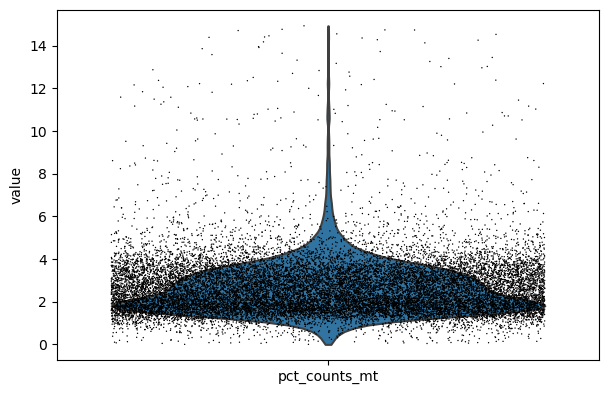

In [23]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [24]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

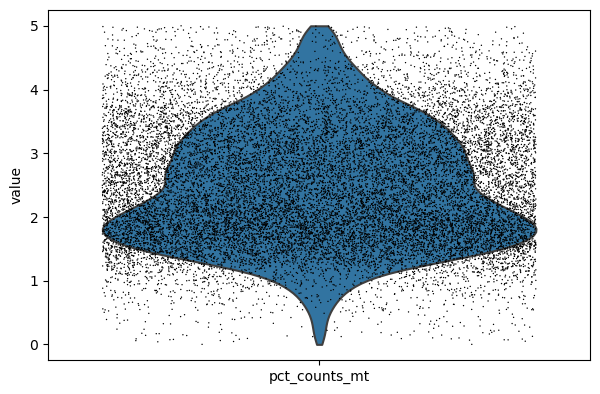

In [25]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [26]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [27]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [45]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [46]:
df["cell_type"] = adata_filtered.obs["cell_type"].to_numpy()

In [47]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [48]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [49]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [50]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [51]:
df

x,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,RP11-54O7.16,...,NLGN4Y,AP000345.2,RP5-1039K5.16,CTA-268H5.14,CH507-513H4.3,AF064858.7,AP001610.5,cell_type,barcode,barcode_cont
0,0.0,0.000000,0.521419,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPvMB,CTGTCTGTCTCACTCTCTCACTGACTGTCTGT-1-1,0
1,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPpHB,GTGTGTGTGTCACTGACTGTGTGACTGTGTGA-1-1,1
2,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPpHB,CTGTGTCAGTCTCTCAGACTCTGTGTGTGTGA-1-1,2
3,0.0,0.729145,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPpHB,GTCTCACACTGTGTCTCTCTGTCTGTGTGTGT-1-1,3
4,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NbpHB,CAGTGTGAGACTCTGTGTCTGTGTGTGAGTGA-1-1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18645,0.0,0.696767,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NbpHB,GTGTGTCAGTGTGTCACAGTCTGACTGTGAGT-3-1;CAGTGTCTG...,17070
18646,0.0,0.000000,0.365293,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPaHB,GTCTCTGTGTGTCTCTCTCAGTGTGTGTCTGT-3-1;GTGTCTGTG...,17071
18647,0.0,0.000000,0.442270,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPpHB,GTCACACTGACTGTCTGAGTCAGTCTGACTGT-3-1,17072
18648,0.0,0.000000,0.707291,0.0,0.0,0.707291,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,I-NPaHB,GTGTCTGAGTGTCTCTCTGTCTGTGTCTCTGT-3-1,17073


In [52]:
df = df.drop("barcode", axis=1)

In [53]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/you_stage1_barcode_all_genes.pkl')

